In [1]:
import sys
sys.path.append("..")

import numpy as np
import tensorflow as tf

from functions import BunDLeNet
from processed_data_storage import ProcessedDataStroage
from preprocess import Preprocessor
from bundle_trainer import BunDLeTrainer
from plot import plot_loss

# "Trainingsepoche" = ein Durchlauf durch alle Trainingsfenster.
# Nicht verwechseln mit den EEG-Epochen (Zeitabschnitte um ein Bild herum).
n_epochs = 6
subjects_range = range(1, 3)

processed_data_storage = ProcessedDataStroage()
preprocessor = Preprocessor()


processed_data_storage.preprocess_and_save_subjects_from_range(subjects_range)
X_train, X_test, labels_train, labels_test, category_per_epoch_all_subs_train, category_per_epoch_all_subs_test = processed_data_storage.read_subjects_from_range(subjects_range)

I0000 00:00:1795347347.834674   36063 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795347347.870222   36063 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795347348.793102   36063 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


None
Arbeitsverzeichnis: /home/bened/bachelor-thesis/notebooks/BunDLe-Net/notebooks
Datenverzeichnis: /home/bened/bachelor-thesis/data/raw/ds005363-download
Lese BrainVision-Aufnahme ein: /home/bened/bachelor-thesis/data/raw/ds005363-download/sub-101/ses-01/eeg/sub-101_ses-01_task-objrecog_eeg.vhdr
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 3301 samples (3.301 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.019

In [2]:
number_of_epochs, number_of_channels, number_of_time_points = X_train.shape
print(f"X_train shape: {X_train.shape}")
print(f"Number of epochs: {number_of_epochs}")
print(f"Number of channels: {number_of_channels}")

# Alle Fensterpaare der Trainingsdaten (darauf wird trainiert)
epoch_numbers, start_time_points = preprocessor.list_all_window_pairs(
    number_of_epochs, number_of_time_points, preprocessor.WINDOW_LENGTH
)

# Alle Fensterpaare der Testdaten (werden nur ausgewertet, nie trainiert)
number_of_test_epochs = X_test.shape[0]
number_of_test_time_points = X_test.shape[2]
test_epoch_numbers, test_start_time_points = preprocessor.list_all_window_pairs(
    number_of_test_epochs, number_of_test_time_points, preprocessor.WINDOW_LENGTH
)

# Feste Zufallsauswahl an Trainingsfenstern, genauso viele wie Testfenster.
# Auf dieser Auswahl messen wir nach jeder Trainingsepoche Loss und Genauigkeit
# auf genau dieselbe Art wie auf den Testdaten.
random_generator = np.random.default_rng(11)
train_subset_indices = random_generator.choice(
    len(epoch_numbers), size=len(test_epoch_numbers), replace=False
)
train_subset_epoch_numbers = epoch_numbers[train_subset_indices]
train_subset_start_time_points = start_time_points[train_subset_indices]

print(f"Trainingsfenster: {len(epoch_numbers)}, davon ausgewertet: {len(train_subset_epoch_numbers)}")
print(f"Testfenster: {len(test_epoch_numbers)}")

# Zufallswert (reines Raten) als Vergleichslinie.
# Das Ziel eines Fensterpaares ist das Label am Index start + WINDOW_LENGTH,
# also frühestens am Index WINDOW_LENGTH. Davor liegende Labels kommen als Ziel nie vor.
target_labels_that_can_occur = labels_train[:, preprocessor.WINDOW_LENGTH:]
target_categories = np.unique(target_labels_that_can_occur)
number_of_target_categories = len(target_categories)
chance_loss = np.log(number_of_target_categories)
chance_accuracy = 1 / number_of_target_categories
print(f"Kategorien, die als Ziel vorkommen: {target_categories}")
print(f"Raten ergibt Loss ln({number_of_target_categories}) = {chance_loss:.3f} und Genauigkeit {chance_accuracy:.2f}")

start_time_in_seconds = -0.2                      
sampling_rate_in_hertz = 100                
times = start_time_in_seconds + np.arange(number_of_time_points) / sampling_rate_in_hertz

X_train shape: (3276, 64, 120)
Number of epochs: 3276
Number of channels: 64
Trainingsfenster: 343980, davon ausgewertet: 86100
Testfenster: 86100
Kategorien, die als Ziel vorkommen: [0. 1. 2. 3. 4.]
Raten ergibt Loss ln(5) = 1.609 und Genauigkeit 0.20


W0000 00:00:1795347377.524437   36063 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1795347377.526367   36063 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1795347377.626052   36063 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9217 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:03:00.0, compute capability: 12.0a


Trainingsepoche 1/6: Loss Training 1.522 / Test 1.523, Genauigkeit Training 0.244 / Test 0.218
Trainingsepoche 2/6: Loss Training 1.510 / Test 1.512, Genauigkeit Training 0.243 / Test 0.217
Trainingsepoche 3/6: Loss Training 1.418 / Test 1.422, Genauigkeit Training 0.270 / Test 0.245
Trainingsepoche 4/6: Loss Training 1.384 / Test 1.391, Genauigkeit Training 0.281 / Test 0.253
Trainingsepoche 5/6: Loss Training 1.371 / Test 1.377, Genauigkeit Training 0.285 / Test 0.255
Trainingsepoche 6/6: Loss Training 1.364 / Test 1.372, Genauigkeit Training 0.284 / Test 0.256


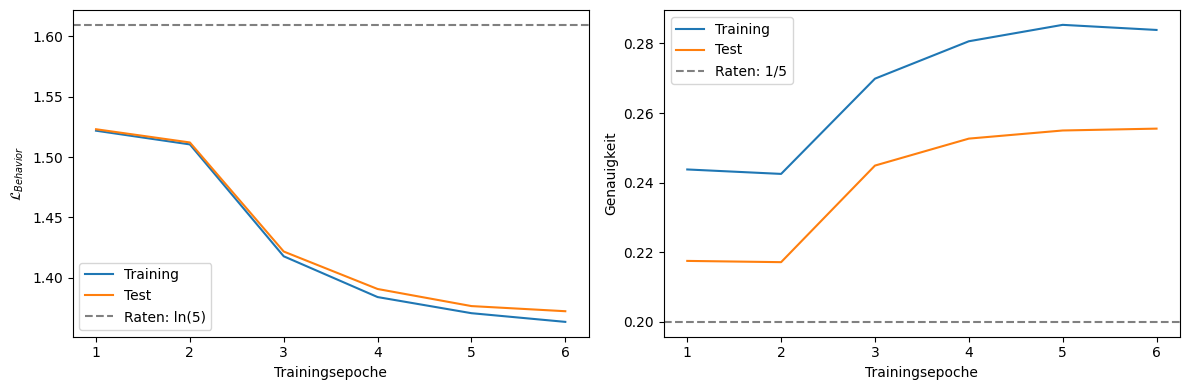

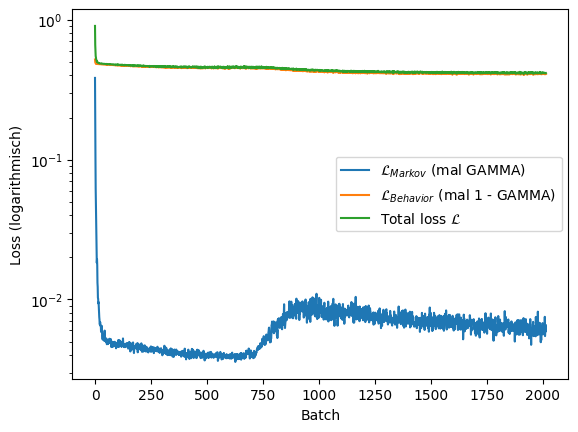

In [3]:
# Modell hier neu anlegen: Wenn man nur diese Zelle erneut ausführt,
# startet das Training von vorne statt mit dem alten Modell weiterzumachen.
model = BunDLeNet(3)
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
trainer = BunDLeTrainer(model, optimizer)
random = np.random.default_rng(11)

bundle_trainer = BunDLeTrainer(model, optimizer)
history_per_epoch, all_losses = bundle_trainer.train_model(X_train, labels_train, X_test, labels_test, epoch_numbers, start_time_points, random, n_epochs)

plot_loss(history_per_epoch, all_losses, chance_loss, number_of_target_categories, chance_accuracy, preprocessor.GAMMA)